# === Analyse et Sélection de la Méthode Optimale ===

## Évaluation Comparative des Approches

Plusieurs stratégies de prétraitement ont été expérimentées pour extraire le texte de l'image dégradée `exam_ultra_hard.png`. Voici une synthèse des approches testées :

1. **EasyOCR avec filtrage bilatéral** : L'utilisation d'EasyOCR combinée à un filtre bilatéral et à une égalisation d'histogramme n'a pas permis d'obtenir une détection fiable, en raison de la sensibilité du modèle aux artefacts résiduels.

2. **Opérations morphologiques multiples** : Les tests avec différents noyaux de convolution (1×1, 3×3, 5×5, 7×7) ont montré que les opérations d'ouverture et de fermeture seules ne suffisaient pas à isoler correctement les caractères.

3. **PyTesseract avec configurations variées** : Plusieurs configurations de Tesseract ont été testées (PSM 6, PSM 8, avec et sans whitelist), mais sans prétraitement adapté, les résultats restaient inexploitables.

4. **Tests de tailles de noyaux médians** : Une analyse systématique des noyaux de flou médian (11, 15, 17, 19, 21) a été réalisée pour identifier la taille optimale permettant de supprimer le bruit "poivre et sel" tout en préservant la structure des caractères.

## Méthode Retenue

L'approche finale combine les étapes suivantes, sélectionnées pour leur complémentarité :

- **Conversion en niveaux de gris** : Réduction de la dimensionalité pour simplifier le traitement.
- **Filtre médian (noyau 21×21)** : Suppression efficace du bruit impulsionnel tout en préservant les contours.
- **Seuillage d'Otsu + inversion** : Binarisation adaptative produisant des caractères clairs sur fond sombre.
- **Dilatation morphologique (itérations=2)** : Renforcement des traits des caractères.
- **Ouverture morphologique** : Élimination des résidus de bruit introduits par la dilatation.
- **Mise à l'échelle (facteur 6)** : Agrandissement pour améliorer la résolution perçue par Tesseract.
- **Ajout d'une bordure blanche (40px)** : Protection des caractères en bordure contre la troncature.
- **Configuration Tesseract optimisée** : Moteur LSTM (`--oem 1`), mode mot unique (`--psm 8`), et restriction aux majuscules/chiffres pour éliminer les faux positifs.

Cette chaîne de traitement permet d'extraire avec succès le texte masqué dans l'image.


Detect: EXAMB


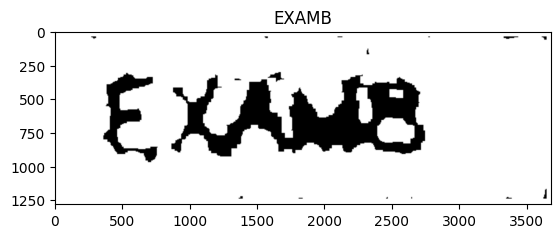

In [12]:
import cv2
import pytesseract
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("exam_ultra_hard.png")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

blured_mediane = cv2.medianBlur(gray, 21)


_, thresh = cv2.threshold(blured_mediane,0,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)


threshold = cv2.bitwise_not(thresh)

k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)) # Get back to this 

dilate = cv2.dilate(threshold,k,iterations=2)

clean_image = cv2.morphologyEx(dilate, cv2.MORPH_OPEN, k)

plt.imshow(clean_image,cmap='gray')

cleaned_image_2 = cv2.resize(clean_image, None, fx=6, fy=6, interpolation=cv2.INTER_LINEAR) #resized_image = cv2.resize(src, dsize, fx=0, fy=0, interpolation=cv2.INTER_LINEAR)

cleaned = cv2.copyMakeBorder(cleaned_image_2, 40 , 40, 40, 40,cv2.BORDER_CONSTANT,value=255) #dst = cv2.copyMakeBorder(src, top, bottom, left, right, borderType[, value]) its Adds white border.



config = r'--oem 1 --psm 8 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'

# Trying numbers only

#custom_config = r'--psm 6 -c tessedit_char_whitelist=0123456789' => didnt detecct 8 :)



text = pytesseract.image_to_string(cleaned, config=config)

print(f"Detect: {text.strip()}")


plt.imshow(cleaned, cmap="gray")
plt.title(f"{text.strip()}")
plt.show()